## Results Pipeline: Clean Theta 0.0

In [1]:
# Imports
import sys # for path management
import os

# Add HandcraftApproach directory to path
ha_path = os.path.abspath("/Users/liviastein/STDP_Theta-1/STDP-SR_scripts/Task_Setup/HandcraftApproach")
if ha_path not in sys.path:
    sys.path.insert(0, ha_path)

import importlib
import MazeAgent_HA as MA
importlib.reload(MA)

import copy
import tomplotlib.tomplotlib as tpl
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
import imageio
import random
import pandas as pd
from tqdm.notebook import tqdm

%load_ext autoreload
%autoreload 1

#for plotting in notebook
%matplotlib inline

# define a list of random seeds to loop through for runs of the same experiment
#random_seeds = [0, 42]
random_seeds = [0, 2, 4, 6, 42]

Setting parameters
Initialising
   making state/history dataframes
   initialising velocity, position and direction
   setting time/run counters
   initialising theta phases: clean and scrambled
   making the maze walls
   setting goal location and reward
   discretising position for later plotting
   handling undefined parameters
   initialising basis features for learning
   calculating state vector at all discretised positions


  0%|          | 0/550000 [00:00<?, ?it/s]

   initialising STDP weight matrix and traces
   Adding 'theta scrambled' Condition
   calculating value function based on distance to goal
DONE


(<Figure size 200x400 with 1 Axes>, <Axes: >)

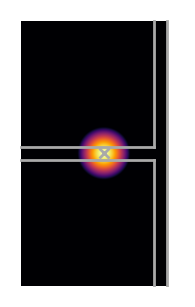

In [2]:
# set up place cells
N = 40
mazeSize = 5.0

# Scale the original TMaze layout to the larger maze
xcen = np.concatenate((
    np.linspace(0.02, 1.00, N) * mazeSize, 
    1.05 * mazeSize * np.ones(N), # 1.05 * mazeSize is the x-coordinate of the rightmost wall of the maze
    1.05 * mazeSize * np.ones(N) # 
))
ycen = np.concatenate((
    np.ones(N) * mazeSize,
    np.linspace(1.03, 2.00, N) * mazeSize, 
    np.linspace(0.97, 0.00, N) * mazeSize
))
centres = np.vstack((xcen, ycen)).T


# set parameters for the MazeAgent class
params = {
           #Maze params 
          'mazeType'            : 'TMaze',  #type of maze, define in getMaze() function
          'stateType'           : 'gaussianThreshold', #feature on which to TD learn (onehot, gaussian, gaussianCS, circles, bump)
          'movementPolicy'      : 'windowsScreensaver',  #movement policy (raudies, random walk, windows screensaver)
          'roomSize'            : mazeSize,          #maze size scaling parameter, metres
          'dt'                  : 0.01,       #simulation time disretisation (defualts to largest )
          'dx'                  : 0.01,       #space discretisation (for plotting, movement is continuous)
          'speedScale'          : 0.16,       #movement speed scale, metres/second
          'rotSpeedScale'       : None,       #rotational speed scale, radians/second
          'initPos'             : None,  #initial position [x0, y0], metres
          'initDir'             : None,      #initial direction, unit vector
          'nCells'              : N,       #how many features to use
          'centres'             : centres,       #array of receptive field positions. Overwrites nCells
          'sigma'               : 1,          #basis cell width scale (irrelevant for onehots)
          'doorsClosed'         : True,       #whether doors are opened or closed in multicompartment maze
          'reorderCells'        : False,       #whether to reorde the cell centres which have been provided
          'firingRateLookUp'    : False,      #use quantised lookup table for firing rates 
          'biasDoorCross'       : False,      #if True, in twoRoom maze door crossings are biased towards
          'biasWallFollow'      : True,       #if True, agent aligns to wall when gets too near.

          #TD params 
          'tau'                 : 4,          #TD decay time, seconds
          'TDdx'                : 0.1,       #rough distance between TD learning updates, metres 
          'alpha'               : 0.01,       #TD learning rate 
          'successorFeatureNorm': 100,        #linear scaling on successor feature definition found to improve learning stability
          'TDreg'               : 0.01,       #L2 regularisation 
          
          #STDP params
          'peakFiringRate'      : 10,          #peak firing rate of a cell (middle of place field,preferred theta phase)
          'tau_STDP_plus'       : 20e-3,      # was 20 pre trace decay time
          'tau_STDP_minus'      : 40e-3,      #was 40 post trace decay time
          'a_STDP'              : -0.4,       # was -0.4, pre-before-post potentiation factor (post-before-pre = 1) 
          'eta'                 : 0.01,       #STDP learning rate
          'baselineFiringRate'  : 0,          #baseline firing rate for cells 
          'use_full_STDP_rule'  : True,      #whether to use full STDP rule     
          'online_mapping'      : 'identity',  #how to map CA3-->CA1 during learning
          'rownorm'             : False,

          #Theta precession params
          'thetaFreq'           : 10,         #theta frequency
          'precessFraction'     : 0.5,        #fraction of 2pi the prefered phase moves through
          'kappa'               : 3.5,          # von mises spread parameter
          
          #Theta scrambling params (Livi addition)
          'scramble_strength'    : 1.0,        # strength of theta phase scrambling 
          'hf_strength'          : 1.0,        # strength of high frequency jitter added to scrambled theta phase

          # Goal Location
          'goalPos'             : [5.25, 8.0], # 7.5 before. position of goal in metres -> given as array of shape [x, y]
          'goalRadius'          : 0.5,       # radius of goal in metres
          'goalReward'          : 1.0,

}

agent_CT = MA.MazeAgent(params)
plotter = MA.Visualiser(agent_CT)
agent_CT.toggleDoors(doorsClosed=False)

#plotter.plotMazeStructure() # plot maze structure to check it's correct before starting simulation
plotter.plotReceptiveField(24) # plot receptive field of place cell 5 in the middel of loop
#plotter.plotFeatureCells(centresOnly=True, textlabel=False) # plots centres of the place cells in maze (no heatmap)
#fig, ax = plotter.plotFeatureCells(shufflebeforeplot=False, textlabel=True)
#plotter.plotGoal()

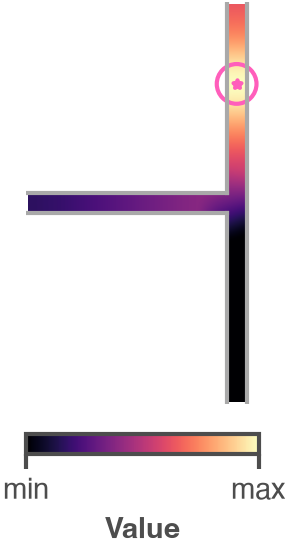

In [3]:
# plot value function
plotter = MA.Visualiser(agent_CT)

plt.style.use('/Users/liviastein/STDP_Theta-1/ResultPipelines/plot_style.mplstyle')

# plot value function
fig = plotter.valueFunctionHeatMap(fig=None, ax=None, smoothing=1, showGoal=True, showCentres=False, save=False)
#plt.savefig("/Users/liviastein/STDP_Theta-1/Final_Figures/ValueFunction2.pdf", transparent=True)

# plot feature cells
#plotter.plotFeatureCells(shufflebeforeplot=False, textlabel=True)


## Pretrain Agent

  0%|          | 0/180000 [00:00<?, ?it/s]

Calculating place and grid cells


(<Figure size 300x300 with 2 Axes>,
 <Axes: title={'center': "SR matrix 'W' after 30min of STDP learning without theta modulation"}>,
 <Axes: >)

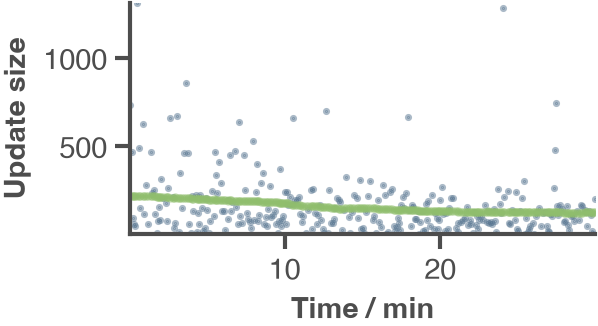

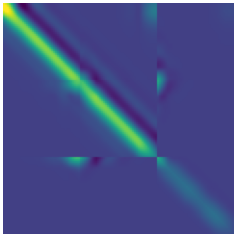

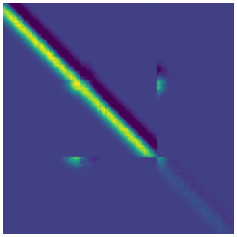

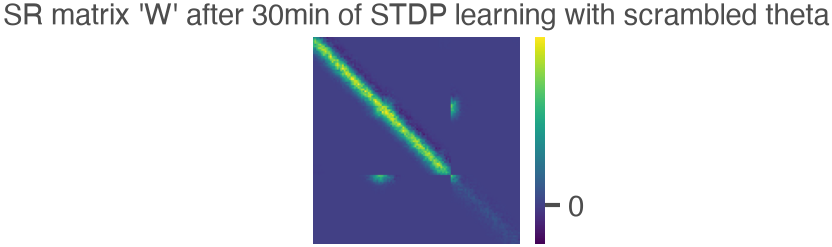

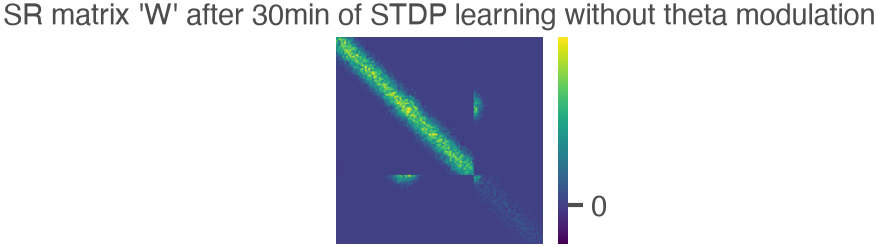

In [4]:
agent_CT.pos = np.array([0, mazeSize]) # start at the stem center in the scaled T maze
agent_CT.dir = np.array([1,0]) # start facing right at the start of the stem
agent_CT.runRat(trainTime=30, STDPLearn=True, TDSRLearn=True, saveEvery=0.5)

# Plot Trajectory for control
plotter = MA.Visualiser(agent_CT)
#fig, ax = plotter.plotMazeStructure()
#plottimestart, plottimeend = 0, 1
# plotter.plotTrajectory(fig=fig, ax=ax, starttime=plottimestart, endtime=plottimeend)

# Plot SRs fro control
plotter.plotM(whichM="M", colorbar=False, title=None, save= False) 
plotter.plotM(whichM="W", colorbar=False, title=None, save=False)
# Plot scrambled
plotter.plotM(whichM="W_scrambled", colorbar=True, title="SR matrix 'W' after 30min of STDP learning with scrambled theta", save=False) 
# Plot no_theta
plotter.plotM(whichM="W_notheta", colorbar=True, title="SR matrix 'W' after 30min of STDP learning without theta modulation", save=False)


## Decision Task

Running seed 0...
Timeout: 90.0s
dt: 0.01s
Steps: 9000
Expected final elapsed: 90.0s
Epsilon threshold: 89.999999999


  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/9500 [00:00<?, ?it/s]

/Users/liviastein/STDP_Theta-1/STDP-SR_scripts/Task_Setup/HandcraftApproach/MazeAgent_HA.py:1030: RuntimeWarning: overflow encountered in exp
  preTrace        *= np.exp(- timeDiff / self.tau_STDP_plus) #traces for all cells decay...
/Users/liviastein/STDP_Theta-1/STDP-SR_scripts/Task_Setup/HandcraftApproach/MazeAgent_HA.py:1030: RuntimeWarning: invalid value encountered in multiply
  preTrace        *= np.exp(- timeDiff / self.tau_STDP_plus) #traces for all cells decay...
/Users/liviastein/STDP_Theta-1/STDP-SR_scripts/Task_Setup/HandcraftApproach/MazeAgent_HA.py:1031: RuntimeWarning: overflow encountered in exp
  postTrace       *= np.exp(- timeDiff / self.tau_STDP_minus) #traces for all cells decay...
/Users/liviastein/STDP_Theta-1/STDP-SR_scripts/Task_Setup/HandcraftApproach/MazeAgent_HA.py:1031: RuntimeWarning: invalid value encountered in multiply
  postTrace       *= np.exp(- timeDiff / self.tau_STDP_minus) #traces for all cells decay...
/Users/liviastein/STDP_Theta-1/STDP-SR_scr

Episode timed out after 95.0 seconds! Starting new episode!
Calculating place and grid cells


  0%|          | 0/9500 [00:00<?, ?it/s]

... (98 outputs left out)

  0%|          | 0/9500 [00:00<?, ?it/s]

Episode timed out after 95.0 seconds! Starting new episode!
Calculating place and grid cells


  0%|          | 0/9500 [00:00<?, ?it/s]

Goal reached! Duration: 74.74999999993202. Starting new episode!
Calculating place and grid cells
SUMMARY FOR SEED 0 ONLY!:
Seed 0 Summary:
  Total Episodes: 10
  Reached Goal: 6
  Timeouts: 4
  Wrong Arm Choices: 0
  Percentage Correct: 60.00%
  Average Time to Goal: 49.50666666662164
SUMMARY FOR SEED 2 ONLY!:
Seed 2 Summary:
  Total Episodes: 10
  Reached Goal: 8
  Timeouts: 2
  Wrong Arm Choices: 0
  Percentage Correct: 80.00%
  Average Time to Goal: 59.82874999996372
SUMMARY FOR SEED 4 ONLY!:
Seed 4 Summary:
  Total Episodes: 10
  Reached Goal: 5
  Timeouts: 5
  Wrong Arm Choices: 0
  Percentage Correct: 50.00%
  Average Time to Goal: 56.00399999995748
SUMMARY FOR SEED 6 ONLY!:
Seed 6 Summary:
  Total Episodes: 10
  Reached Goal: 4
  Timeouts: 6
  Wrong Arm Choices: 0
  Percentage Correct: 40.00%
  Average Time to Goal: 53.32999999996268
SUMMARY FOR SEED 42 ONLY!:
Seed 42 Summary:
  Total Episodes: 10
  Reached Goal: 8
  Timeouts: 2
  Wrong Arm Choices: 0
  Percentage Correct: 80.0

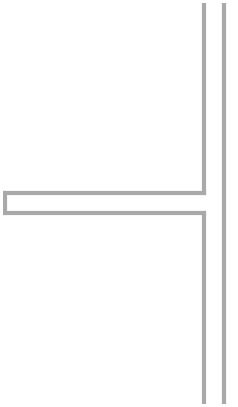

In [5]:
# adapt maze and close off open stem
if agent_CT.mazeType == "TMaze":
    rs = agent_CT.roomSize
    corridor_half_width = 0.05 * rs
    agent_CT.walls['CloseStem'] = np.array([[[0.0, rs-corridor_half_width], [0.0, rs+corridor_half_width]]])
    agent_CT.mazeState['walls'] = agent_CT.walls.copy()
    agent_CT.toggleDoors(doorsClosed=False)
    agent_CT.discreteStates = agent_CT.positionArray_to_stateArray(agent_CT.discreteCoords, stateType= agent_CT.stateType)
    snapshot = pd.DataFrame({'t': [agent_CT.t], 'M': [agent_CT.M.copy()], 'W': [agent_CT.W.copy()], 'W_notheta':[agent_CT.W_notheta.copy()], 'W_scrambled':[agent_CT.W_scrambled.copy()], 'mazeState':[agent_CT.mazeState]})
    agent_CT.snapshots = pd.concat([agent_CT.snapshots, snapshot], ignore_index=True)

# check if maze is changed correctly
plotter = MA.Visualiser(agent_CT)
plotter.plotMazeStructure()

# run a number of task episodes with pretrained agent (agent_CT) for each random seed in the list defined earlier, and save results for each seed in a dictionary
results = {}
for seed in random_seeds:
    print(f"Running seed {seed}...")
    np.random.seed(seed); random.seed(seed)

    # save results for seed
    results[seed] = {'episode_logs': [], "episodes": [], "params": params} # to store outcome of each episode for this seed, which we will later use to summarise performance across seeds

    # snapshot agent baseline state 
    base_history_len = len(agent_CT.history)
    base_snap_len = len(agent_CT.snapshots)
    baseline_t = agent_CT.t

    #baseline_theta = getattr(agent_CT, "thetaPhase", 0.0)
    #baseline_theta_scrambled = getattr(agent_CT, "thetaPhase_scrambled", 0.0)
    #baseline_spikedata = copy.deepcopy(getattr(agent_CT, "spikedata", {}))
    #baseline_spikedata_by_condition = copy.deepcopy(getattr(agent_CT, "spikedata_by_condition", {}))
    #baseline_decoded = copy.deepcopy(getattr(agent_CT, "decoded_dir_history", []))
    baseline_runID = agent_CT.runID

    M_before = agent_CT.M.copy()
    W_before = agent_CT.W.copy()
    W_notheta_before = agent_CT.W_notheta.copy()
    W_scrambled_before = agent_CT.W_scrambled.copy()

    # reset episode-local state (clean start, keep weights)
    agent_CT.pos = np.array([0.2, mazeSize])            # or [0, mazeSize] per your convention
    agent_CT.dir = np.array([1.0, 0.0])
    agent_CT.speed = agent_CT.speedScale
    agent_CT.t = 0.0
    agent_CT.thetaPhase = 0.0
    agent_CT.thetaPhase_scrambled = 0.0
    agent_CT.thetaPhase_scrambled_history = []
    agent_CT.thetaPhase_scrambled_time_history = []

    agent_CT.spikedata = {'CA3': {'times': [], 'ids': []}, 'CA1': {'times': [], 'ids': []}}
    agent_CT.spikedata_by_condition = {
        'theta': {'CA1': {'times': [], 'ids': []}, 'CA3': {'times': [], 'ids': []}},
        'notheta': {'CA1': {'times': [], 'ids': []}, 'CA3': {'times': [], 'ids': []}},
        'scrambled': {'CA1': {'times': [], 'ids': []}, 'CA3': {'times': [], 'ids': []}}
    }
    agent_CT.decoded_dir_history = []
    agent_CT.reachedGoal = False
    agent_CT.goalReachedTime = 0.0
    agent_CT.lastTurnUpdate = -1
    agent_CT.randomTurnSpeed = 0
    agent_CT.doorPassage = False
    agent_CT.doorPassageTime = 0.0

    # Diagnostic: check timeout condition behavior
    timeout_test = 90.0
    dt_test = agent_CT.dt
    steps_test = int(timeout_test / dt_test)
    print(f"Timeout: {timeout_test}s")
    print(f"dt: {dt_test}s")
    print(f"Steps: {steps_test}")
    print(f"Expected final elapsed: {steps_test * dt_test}s")
    print(f"Epsilon threshold: {timeout_test - 1e-9}")


    # run decision task episodes
    episodes = 10
    for ep in tqdm(range(episodes)):
        history_start = len(agent_CT.history)
        snapshot_start = len(agent_CT.snapshots)
        t_start = agent_CT.t
        runid_start = agent_CT.runID
        decoded_dir_start = len(agent_CT.decoded_dir_history)


        outcome = agent_CT.TaskEpisode(saveEvery=0.5, 
                                        TDSRLearn=False, 
                                        STDPLearn=True, 
                                        condition = 'theta', 
                                        phase_threshold = 1.5*np.pi, 
                                        t_window =None,
                                        updateSTDPWeights = False,
                                        maxTurnAngle = True,
                                        maxAngle = 50.0,
                                        timeout = 95.0) # 95-5 as margin 
        # store outcome of episode
        history_end = len(agent_CT.history)
        snapshot_end = len(agent_CT.snapshots)
        t_end = agent_CT.t
        runid_end = agent_CT.runID
        decoded_dir_end = len(agent_CT.decoded_dir_history)

        assert runid_end == runid_start + 1, (
              f"runID mismatch at seed={seed}, ep={ep}: "
              f"start={runid_start}, end={runid_end}"
        )

        # metadata row for this episode
        metadata = {
            'seed': seed,
            'episode': ep,
            'runID_start': runid_start,
            'runID_end': runid_end,
            't_start': t_start,
            't_end': t_end,
            "duration": t_end - t_start,
            "history_start": history_start,
            "history_end": history_end,
            "snapshot_start": snapshot_start,
            "snapshot_end": snapshot_end,
            "outcome": outcome
        }
        results[seed]['episode_logs'].append(metadata)

        # payload data for this episode
        payload = {"history": agent_CT.history.iloc[history_start:history_end].reset_index(drop=True),
                   "decoded_dir_history": agent_CT.decoded_dir_history[decoded_dir_start:decoded_dir_end],
                     "snapshots": agent_CT.snapshots.iloc[snapshot_start:snapshot_end].reset_index(drop=True),
                     "spikedata": copy.deepcopy(agent_CT.spikedata),
                     "spikedata_by_condition": copy.deepcopy(agent_CT.spikedata_by_condition),
                     "final_weights": {
                          'M': agent_CT.M.copy(),
                          'W': agent_CT.W.copy(),
                          'W_notheta': agent_CT.W_notheta.copy(),
                          'W_scrambled': agent_CT.W_scrambled.copy()
                     }
          }       
        results[seed]['episodes'].append(payload)

    # save final outcome/weights if desired
    results[seed]["final_weights_pre_restore"] = {
        "M": agent_CT.M.copy(), "W": agent_CT.W.copy(),
        "W_notheta": agent_CT.W_notheta.copy(), "W_scrambled": agent_CT.W_scrambled.copy()
    }

    # 6) restore agent to baseline (clean reset) so next seed starts from same pretrained state
    agent_CT.M = M_before
    agent_CT.W = W_before
    agent_CT.W_notheta = W_notheta_before
    agent_CT.W_scrambled = W_scrambled_before
    agent_CT.history = agent_CT.history.iloc[:base_history_len].reset_index(drop=True)
    agent_CT.snapshots = agent_CT.snapshots.iloc[:base_snap_len].reset_index(drop=True)
    agent_CT.t = baseline_t
    agent_CT.runID = baseline_runID

# restore original maze -> open stem again
if 'CloseStem' in getattr(agent_CT, 'walls', {}):
                del agent_CT.walls['CloseStem'] # remove wall closing stem after decision task is done, so agent can explore whole maze again
                agent_CT.mazeState['walls'] = agent_CT.walls.copy()
                agent_CT.toggleDoors(doorsClosed = False) # make sure right arm is open again
                agent_CT.discreteStates = agent_CT.positionArray_to_stateArray(agent_CT.discreteCoords, stateType=agent_CT.stateType) # recalculate discrete states to account for removed wall 
            
# summarise performance results per seed episodes and across seeds: i.e. get reward count, total reward, number of timeouts, number of wrong arm choices, and average time to reach goal.
summary = []
for seed, data in results.items():
    episode_logs = data['episode_logs']
    episodes = data['episodes']

    # summarise for one seed
    outcome_rows = []
    for log in episode_logs:
        outcome = log['outcome']
        if outcome['reward_count'] > 0:
            label = 'reached_goal'
        elif outcome['wrong_arm_count'] > 0:
            label = 'wrong_arm'
        elif outcome['timeout_count'] > 0:
            label = 'timeout'
        else:
            label = 'unknown'
        outcome_rows.append({'label': label, 'duration': log['duration']})

    outcome_df = pd.DataFrame(outcome_rows)
    seed_summary = {
        'seed': seed,
        'total_episodes': len(episode_logs),
        'reached_goal': int((outcome_df['label'] == 'reached_goal').sum()),
        'timeouts': int((outcome_df['label'] == 'timeout').sum()),
        'wrong_arm': int((outcome_df['label'] == 'wrong_arm').sum()),
        'percentage_correct': float((outcome_df['label'] == 'reached_goal').sum()) / len(outcome_df) if len(outcome_df) > 0 else np.nan,
        'average_time_to_goal': float(outcome_df.loc[outcome_df['label'] == 'reached_goal', 'duration'].mean()) if (outcome_df['label'] == 'reached_goal').any() else np.nan
    }
    summary.append(seed_summary)
    # print summary for this seed
    print(f"SUMMARY FOR SEED {seed} ONLY!:")
    print(f"Seed {seed} Summary:")
    print(f"  Total Episodes: {seed_summary['total_episodes']}")
    print(f"  Reached Goal: {seed_summary['reached_goal']}")
    print(f"  Timeouts: {seed_summary['timeouts']}")
    print(f"  Wrong Arm Choices: {seed_summary['wrong_arm']}")
    print(f"  Percentage Correct: {seed_summary['percentage_correct']:.2%}")
    print(f"  Average Time to Goal: {seed_summary['average_time_to_goal']}")
    print("========================================")

# summary across seeds
total_episodes = sum(s['total_episodes'] for s in summary)
total_reached_goal = sum(s['reached_goal'] for s in summary)
total_timeouts = sum(s['timeouts'] for s in summary)
total_wrong_arm = sum(s['wrong_arm'] for s in summary)
goal_times = [s['average_time_to_goal'] for s in summary if not np.isnan(s['average_time_to_goal'])]
average_time_to_goal = float(np.mean(goal_times)) if len(goal_times) > 0 else np.nan
print(f"Overall Summary Across Seeds {random_seeds}:")
print(f"  Total Episodes: {total_episodes}")
print(f"  Reached Goal: {total_reached_goal}")
print(f"  Timeouts: {total_timeouts}")
print(f"  Wrong Arm Choices: {total_wrong_arm}")
print(f"  Average Time to Goal: {average_time_to_goal}")
print(f"  Percentage Correct: {total_reached_goal / total_episodes:.2%}" if total_episodes > 0 else np.nan)
print("========================================")


## Save Data

In [6]:
import pickle

checkpoint_path = "/Users/liviastein/STDP_Theta-1/Results_expScale/checkpointsExp/Clean00_results.pkl"

state = {
    "results": results,
    "params": params,
    "random_seeds": random_seeds,
    "maze_walls": agent_CT.walls,
    "maze_state": agent_CT.mazeState,
    # add these once you compute them, if you want them bundled too:
    # "summary": summary,
    # "episode_table": episode_table,
    # "seed_summary_table": seed_summary_table,
}

with open(checkpoint_path, "wb") as f:
    pickle.dump(state, f)

print(f"Saved full checkpoint to {checkpoint_path}")

Saved full checkpoint to /Users/liviastein/STDP_Theta-1/Results_expScale/checkpointsExp/Clean00_results.pkl


## Summarise in Table and Export

In [6]:
from pathlib import Path

theta_condition = "Clean00_K3.5"  # change this in each notebook
out_dir = Path("/Users/liviastein/STDP_Theta-1/Results_expScale/KappaSweep_Tables")
out_dir.mkdir(parents=True, exist_ok=True)

rows = []
for seed, data in results.items():
    for log in data["episode_logs"]:
        outcome = log.get("outcome", {})
        if outcome.get("reward_count", 0) > 0:
            label = "reached_goal"
        elif outcome.get("wrong_arm_count", 0) > 0:
            label = "wrong_arm"
        elif outcome.get("timeout_count", 0) > 0:
            label = "timeout"
        else:
            label = "unknown"

        rows.append({
            "theta_condition": theta_condition,
            "seed": seed,
            "episode": log.get("episode"),
            "label": label,
            "duration": log.get("duration", np.nan),
            "reward_count": outcome.get("reward_count", 0),
            "wrong_arm_count": outcome.get("wrong_arm_count", 0),
            "timeout_count": outcome.get("timeout_count", 0),
        })

episode_table = pd.DataFrame(rows)

seed_summary_table = (
    episode_table.groupby(["theta_condition", "seed"], as_index=False)
    .agg(
        total_episodes=("episode", "count"),
        reached_goal=("label", lambda s: int((s == "reached_goal").sum())),
        wrong_arm=("label", lambda s: int((s == "wrong_arm").sum())),
        timeouts=("label", lambda s: int((s == "timeout").sum())),
        percentage_correct=("label", lambda s: float((s == "reached_goal").sum()) / len(s) if len(s) > 0 else np.nan),
        average_time_to_goal=("duration", lambda s: float(s[episode_table.loc[s.index, "label"] == "reached_goal"].mean())
                              if (episode_table.loc[s.index, "label"] == "reached_goal").any() else np.nan),
    )
)

episode_table.to_csv(out_dir / f"{theta_condition}_episode_table.csv", index=False)
seed_summary_table.to_csv(out_dir / f"{theta_condition}_seed_summary_table.csv", index=False)

print(episode_table.head())
print("===============================")
print(seed_summary_table)

  theta_condition  seed  episode         label  duration  reward_count  \
0    Clean00_K3.5     0        0       timeout     90.00             0   
1    Clean00_K3.5     0        1       timeout     90.01             0   
2    Clean00_K3.5     0        2  reached_goal     46.61             1   
3    Clean00_K3.5     0        3  reached_goal     45.86             1   
4    Clean00_K3.5     0        4  reached_goal     47.72             1   

   wrong_arm_count  timeout_count  
0                0              1  
1                0              1  
2                0              0  
3                0              0  
4                0              0  
  theta_condition  seed  total_episodes  reached_goal  wrong_arm  timeouts  \
0    Clean00_K3.5     0              10             6          0         4   
1    Clean00_K3.5     2              10             8          0         2   
2    Clean00_K3.5     4              10             5          0         5   
3    Clean00_K3.5     6    